# Book Recommender on a Medallion Data Lake

**Data Mining Lab Assignment 2**

**Name:** Abhay Prasad
**Roll number:** LIT2023006

This notebook takes the raw **Book-Crossing** dataset (users, books and book ratings) through a Bronze → Silver → Gold data lake and uses the Gold layer to build an **item-based collaborative-filtering** recommender that suggests books to a user.

| Layer | Folder | What it holds |
|---|---|---|
| Bronze | `bronze/` | The three source tables exactly as read from the CSV files, plus `ingestion_timestamp`, each saved as a folder of Parquet part files |
| Silver | `silver/` | Cleaned, typed and de-duplicated tables, filtered to users and books with enough ratings |
| Gold | `gold/` | Sparse user-book rating matrix, book lookup table, and user-level and book-level aggregates |

**How to run:** open the notebook in Google Colab and choose **Runtime → Run all**. The first cells download the dataset, so no upload or Drive mount is needed. The notebook also runs in local Jupyter with Python 3.10+, pandas, NumPy, SciPy, scikit-learn, PyArrow and Matplotlib.

## 0. Setup

In [1]:
import hashlib
import html
import re
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy import sparse
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 160)

DATA_URL = 'https://cdn.freecodecamp.org/project-data/books/book-crossings.zip'
DATA_SHA256 = 'adc7b47afb47c8e29e5f0b70a9816569b3367c5588064ba7a916f16e3ef5d060'
SOURCE_FILES = {'books': 'BX-Books.csv', 'users': 'BX-Users.csv', 'ratings': 'BX-Book-Ratings.csv'}

# Data lake folders (relative to the working directory: /content in Colab)
RAW, BRONZE, SILVER, GOLD = Path('raw'), Path('bronze'), Path('silver'), Path('gold')
for folder in (RAW, BRONZE, SILVER, GOLD):
    folder.mkdir(parents=True, exist_ok=True)

MIN_RATINGS = 10    # minimum ratings per user and per book (chosen in Step 3.8)
HIGH_RATING = 8     # a rating of 8, 9 or 10 counts as "rated highly"
N_NEIGHBOURS = 50   # most similar books stored for every book
SEED = 42

# Chart style: one hue per single-series chart, quiet axes and grid
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'axes.grid.axis': 'y',
    'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': MUTED, 'ytick.color': MUTED,
})

print(f'pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}')

pandas 2.2.2 | numpy 2.0.2 | scikit-learn 1.6.1


## Step 1: Bronze layer

Download the Book-Crossing zip, confirm it is the expected file, and extract the three CSV files into `raw/`.

In [2]:
zip_path = RAW / 'book-crossings.zip'
if not zip_path.exists():
    # The CDN rejects Python's default User-Agent (HTTP 403), so send a browser-style one
    request = urllib.request.Request(DATA_URL, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(request, timeout=120) as response:
        zip_path.write_bytes(response.read())

digest = hashlib.sha256(zip_path.read_bytes()).hexdigest()
assert digest == DATA_SHA256, f'Unexpected source file, sha256 = {digest}'

with zipfile.ZipFile(zip_path) as zf:
    zf.extractall(RAW)
    for info in zf.infolist():
        print(f'{info.filename:22s} {info.file_size / 1e6:5.1f} MB')
print('source sha256:', digest)

BX-Book-Ratings.csv     30.7 MB
BX-Books.csv            77.8 MB
BX-Users.csv            12.3 MB
source sha256: adc7b47afb47c8e29e5f0b70a9816569b3367c5588064ba7a916f16e3ef5d060


The files need three reading options:

* **Separator:** fields are separated by `;`, not `,`.
* **Encoding:** the files are not valid UTF-8, so they are read as Latin-1, which maps every byte to one character and never fails.
* **Escaped quotes:** titles such as `Of Mice and Men (Steinbeck \"Essentials\")` escape inner quotes with a backslash, so `escapechar='\\'` is needed. Without it, line 6,452 of `BX-Books.csv` splits into 9 fields instead of 8.

The cell below shows both failures. To keep Bronze an untouched copy, every column is read as text and nothing is converted to a missing value (`keep_default_na=False`). For example, the literal `NULL` in the `Age` column stays exactly as it is in the file. Each Bronze table is saved as a folder of 4 zstd-compressed Parquet part files (for example `bronze/books/part-0.parquet` to `part-3.parquet`), the same layout Spark uses for data-lake tables. This keeps every file at 3 MB or less and does not change any value.

In [3]:
books_csv = RAW / SOURCE_FILES['books']
for label, options in [('UTF-8 + escape char', dict(encoding='utf-8', escapechar='\\')),
                       ('Latin-1, no escape char', dict(encoding='latin-1'))]:
    try:
        pd.read_csv(books_csv, sep=';', dtype=str, **options)
        print(f'{label:25s} -> read without error')
    except (UnicodeDecodeError, pd.errors.ParserError) as err:
        print(f'{label:25s} -> {type(err).__name__}: {str(err).strip()[:90]}')

UTF-8 + escape char       -> UnicodeDecodeError: 'utf-8' codec can't decode byte 0xc3 in position 26: invalid continuation byte
Latin-1, no escape char   -> ParserError: Error tokenizing data. C error: Expected 8 fields in line 6452, saw 9


In [4]:
READ_OPTIONS = dict(sep=';', encoding='latin-1', escapechar='\\', dtype=str,
                    keep_default_na=False, na_filter=False)
ingestion_timestamp = pd.Timestamp.now(tz='UTC').floor('s')
BRONZE_PARTS = 4

def write_bronze(df, name, parts=BRONZE_PARTS):
    """Save a table as bronze/<name>/part-0.parquet ... part-3.parquet (zstd-compressed, data unchanged)."""
    folder = BRONZE / name
    folder.mkdir(exist_ok=True)
    for old in folder.glob('part-*.parquet'):
        old.unlink()
    for i, rows in enumerate(np.array_split(np.arange(len(df)), parts)):
        df.iloc[rows].to_parquet(folder / f'part-{i}.parquet', index=False,
                                 compression='zstd', compression_level=19)

def read_bronze(name):
    """Read a Bronze table back by concatenating its part files in order."""
    parts = sorted((BRONZE / name).glob('part-*.parquet'), key=lambda p: int(p.stem.split('-')[1]))
    return pd.concat([pd.read_parquet(p) for p in parts], ignore_index=True)

bronze = {}
for name, filename in SOURCE_FILES.items():
    df = pd.read_csv(RAW / filename, **READ_OPTIONS)
    df['ingestion_timestamp'] = ingestion_timestamp
    write_bronze(df, name)
    bronze[name] = df
    print(f'bronze/{name + "/":9s} {len(df):>9,} rows x {df.shape[1]} columns in {BRONZE_PARTS} part files')

# Read each table back: Bronze must hold exactly what was read from the CSV
for name, df in bronze.items():
    pd.testing.assert_frame_equal(read_bronze(name), df, check_dtype=False)
print('Bronze read-back matches the source tables')

bronze/books/      271,379 rows x 9 columns in 4 part files


bronze/users/      278,858 rows x 4 columns in 4 part files


bronze/ratings/  1,149,780 rows x 4 columns in 4 part files


Bronze read-back matches the source tables


In [5]:
for name, df in bronze.items():
    print(f'\n{name}')
    display(df.head(3))


books


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg,2026-11-26 15:14:35+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg,2026-11-26 15:14:35+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ.jpg,2026-11-26 15:14:35+00:00



users


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NULL,2026-11-26 15:14:35+00:00
1,2,"stockton, california, usa",18,2026-11-26 15:14:35+00:00
2,3,"moscow, yukon territory, russia",NULL,2026-11-26 15:14:35+00:00



ratings


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-26 15:14:35+00:00
1,276726,0155061224,5,2026-11-26 15:14:35+00:00
2,276727,0446520802,0,2026-11-26 15:14:35+00:00


## Step 2: Explore the Bronze data (EDA)

All analysis in this step reads the Bronze Parquet files back from disk. Bronze stores every value as text, so numbers are converted with `pd.to_numeric(..., errors='coerce')` only for the analysis. The Bronze files themselves are not changed.

In [6]:
b_books = read_bronze('books')
b_users = read_bronze('users')
b_ratings = read_bronze('ratings')

### 2.1 Shape, data types and missing values

The source has no real empty cells, so missing data shows up as placeholder text (`NULL`, `n/a`, `unknown`, ...). The report below counts both.

In [7]:
PLACEHOLDERS = {'', 'null', 'n/a', '"n/a"', 'na', 'n.a.', 'none', 'unknown', 'nowhere',
                '-', '.', '?', 'x', '_', 'not applicable (na )'}

def missing_report(name, df):
    rows = []
    for col in df.columns:
        s = df[col]
        text = s.astype(str).str.strip().str.lower()
        rows.append({'table': name, 'column': col, 'dtype': str(s.dtype),
                     'null': int(s.isna().sum()),
                     'empty_or_placeholder': int(text.isin(PLACEHOLDERS).sum())})
    return rows

for name, df in [('books', b_books), ('users', b_users), ('ratings', b_ratings)]:
    print(f'{name:8s} shape = {df.shape}')
report = pd.DataFrame([row for name, df in [('books', b_books), ('users', b_users), ('ratings', b_ratings)]
                       for row in missing_report(name, df)])
display(report)

loc_parts = b_users['Location'].str.split(',').explode().str.strip().str.strip('"').str.lower()
loc_missing = loc_parts.isin(PLACEHOLDERS).groupby(level=0).any()
print(f'Users whose Location has an empty or placeholder part: {loc_missing.sum():,} '
      f'({loc_missing.mean():.1%})')

books    shape = (271379, 9)
users    shape = (278858, 4)
ratings  shape = (1149780, 4)


,table,column,dtype,null,empty_or_placeholder
0,books,ISBN,object,0,0
1,books,Book-Title,object,0,1
2,books,Book-Author,object,0,343
3,books,Year-Of-Publication,object,0,0
4,books,Publisher,object,0,3
5,books,Image-URL-S,object,0,0
6,books,Image-URL-M,object,0,0
7,books,Image-URL-L,object,0,0
8,books,ingestion_timestamp,"datetime64[us, UTC]",0,0
9,users,User-ID,object,0,0


Users whose Location has an empty or placeholder part: 19,265 (6.9%)


**Finding 2.1:** Books has 271,379 rows × 9 columns, users 278,858 × 4 and ratings 1,149,780 × 4. Every source column is text, which is expected because Bronze keeps the raw strings. No cell is truly empty, but 110,762 user ages (39.7%) are the text `NULL`, 343 authors are placeholders such as `Not Applicable (Na )` or `Unknown`, and 19,265 users (6.9%) have an empty or `n/a` part in `Location`. **Silver:** cast IDs, ratings, ages and years to numbers, turn placeholders into nulls, and impute the missing ages.

### 2.2 Distribution of ratings

Book-Rating,0,1,2,3,4,5,6,7,8,9,10
ratings,716109.0000,1770.0000,2759.0000,5996.0000,8904.0000,50974.0000,36924.0000,76457.0000,103736.0000,67541.0000,78610.0000
share,0.6228,0.0015,0.0024,0.0052,0.0077,0.0443,0.0321,0.0665,0.0902,0.0587,0.0684


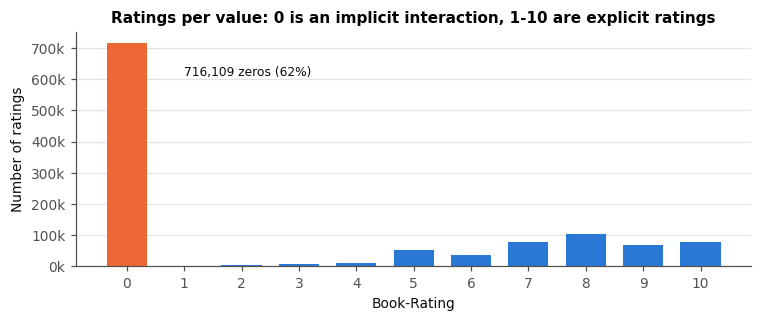

Explicit ratings (1-10): 433,671; mean of explicit ratings = 7.60


In [8]:
rating_num = pd.to_numeric(b_ratings['Book-Rating'], errors='coerce')
rating_counts = rating_num.value_counts().sort_index()
display(pd.DataFrame({'ratings': rating_counts, 'share': (rating_counts / len(rating_num)).round(4)}).T)

fig, ax = plt.subplots(figsize=(7, 3))
colors = [ORANGE if value == 0 else BLUE for value in rating_counts.index]
ax.bar(rating_counts.index, rating_counts.values, color=colors, width=0.7)
ax.set_xticks(rating_counts.index)
ax.set_xlabel('Book-Rating')
ax.set_ylabel('Number of ratings')
ax.set_title('Ratings per value: 0 is an implicit interaction, 1-10 are explicit ratings')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v / 1e3:,.0f}k'))
zeros = rating_counts.loc[0]
ax.annotate(f'{zeros:,} zeros ({zeros / len(rating_num):.0%})', xy=(0, zeros), xytext=(1.0, zeros * 0.9),
            color=INK, fontsize=8, va='top')
plt.tight_layout()
plt.show()
print(f'Explicit ratings (1-10): {(rating_num > 0).sum():,}; mean of explicit ratings = '
      f'{rating_num[rating_num > 0].mean():.2f}')

**Finding 2.2:** 716,109 of the 1,149,780 ratings (62.3%) are 0. A 0 means the user interacted with the book without rating it, so it is not a score. The 433,671 explicit ratings (1-10) lean positive: the most common value is 8 and the mean is 7.60. **Silver:** remove the 0s and keep only ratings from 1 to 10.

### 2.3 User ages and publication years

Age   : {'count': 168096.0, 'mean': 34.8, 'std': 14.4, 'min': 0.0, '25%': 24.0, '50%': 32.0, '75%': 44.0, 'max': 244.0}
  missing (NULL) = 110,762, below 5 = 882, above 100 = 366, max = 244
Year  : {'count': 271379.0, 'mean': 1959.8, 'std': 258.0, 'min': 0.0, '25%': 1989.0, '50%': 1995.0, '75%': 2000.0, 'max': 2050.0}
  year 0 = 4,619, future (> 2026) = 11 [2030, 2037, 2038, 2050], before 1900 = 4 [1376, 1378, 1806, 1897]
  after the 2004 data collection (2005-2026) = 61


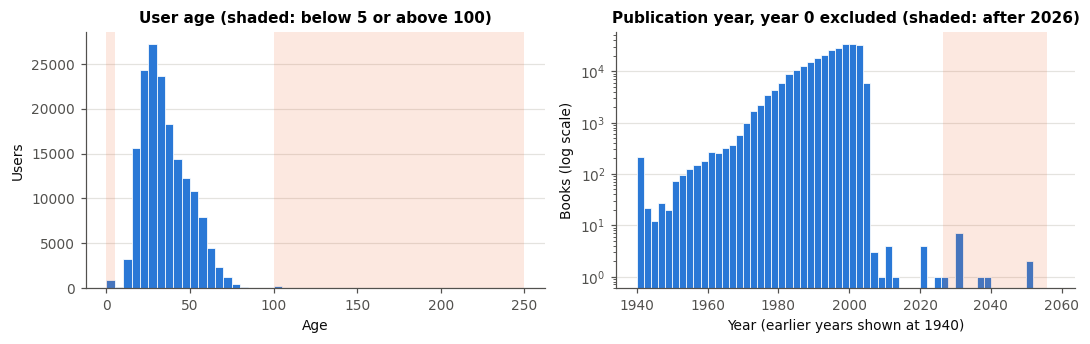

In [9]:
age = pd.to_numeric(b_users['Age'], errors='coerce')
year = pd.to_numeric(b_books['Year-Of-Publication'], errors='coerce')
current_year = b_books['ingestion_timestamp'].iloc[0].year

print('Age   :', age.describe().round(1).to_dict())
print(f'  missing (NULL) = {age.isna().sum():,}, below 5 = {(age < 5).sum():,}, '
      f'above 100 = {(age > 100).sum():,}, max = {age.max():.0f}')
print('Year  :', year.describe().round(1).to_dict())
print(f'  year 0 = {(year == 0).sum():,}, future (> {current_year}) = {(year > current_year).sum():,} '
      f'{sorted(year[year > current_year].astype(int).unique().tolist())}, '
      f'before 1900 = {((year > 0) & (year < 1900)).sum()} '
      f'{sorted(year[(year > 0) & (year < 1900)].astype(int).unique().tolist())}')
print(f'  after the 2004 data collection (2005-{current_year}) = {year.between(2005, current_year).sum()}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(age.dropna(), bins=np.arange(0, 250, 5), color=BLUE, edgecolor='white', linewidth=0.5)
axes[0].axvspan(0, 5, color=ORANGE, alpha=0.15, lw=0)
axes[0].axvspan(100, 250, color=ORANGE, alpha=0.15, lw=0)
axes[0].set_title('User age (shaded: below 5 or above 100)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Users')

year_plot = year.clip(lower=1940, upper=2055)
axes[1].hist(year_plot[year > 0], bins=np.arange(1940, 2060, 2), color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].axvspan(current_year + 0.5, 2056, color=ORANGE, alpha=0.15, lw=0)
axes[1].set_yscale('log')
axes[1].set_title(f'Publication year, year 0 excluded (shaded: after {current_year})')
axes[1].set_xlabel('Year (earlier years shown at 1940)')
axes[1].set_ylabel('Books (log scale)')
plt.tight_layout()
plt.show()

**Finding 2.3 (ages):** Ages range from 0 to 244. 882 users are under 5 and 366 are over 100, which are impossible ages for someone rating books. 110,762 ages are missing, and the plausible ages have a median of 32. **Silver:** set ages below 5 or above 100 to null, then fill every null with the median age, and keep a flag recording which ages were imputed.

**Finding 2.3 (years):** 4,619 books have publication year 0, and 11 have years after 2026 (2030, 2037, 2038 and 2050). There are also 4 implausibly early years (1376, 1378, 1806, 1897) and 61 years between 2005 and 2026, after the 2004 data collection. **Silver:** set year 0 and future years to null, as the assignment asks. The early and post-2004 years are kept, because they cannot be corrected safely and the recommender does not use the year.

### 2.4 Number of ratings per user and per book

,count,median,75%,90%,99%,max,share with 1 rating,share with >= 10
users: all ratings,105283.0,1.0,4.0,12.0,174.0,13602.0,0.562,0.124
users: explicit (1-10),77805.0,1.0,3.0,9.0,73.0,8524.0,0.583,0.094
books: all ratings,340556.0,1.0,2.0,6.0,36.0,2502.0,0.579,0.054
books: explicit (1-10),185973.0,1.0,2.0,4.0,22.0,707.0,0.697,0.030


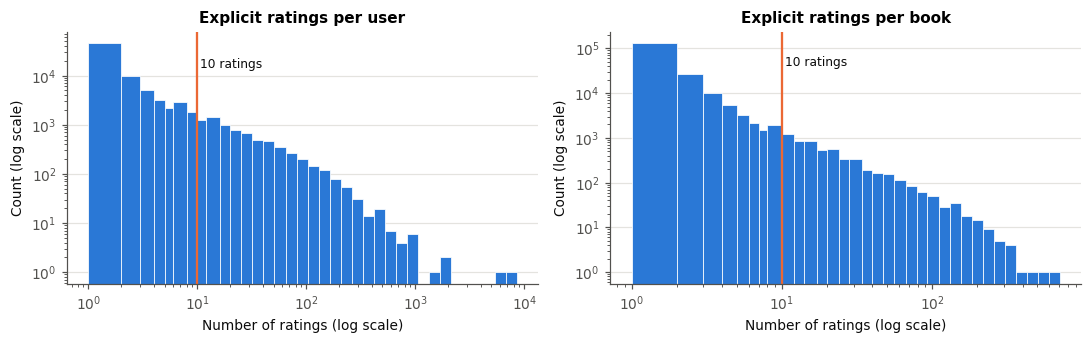

In [10]:
explicit = b_ratings[rating_num > 0]
per_user = {'all ratings': b_ratings.groupby('User-ID').size(), 'explicit (1-10)': explicit.groupby('User-ID').size()}
per_book = {'all ratings': b_ratings.groupby('ISBN').size(), 'explicit (1-10)': explicit.groupby('ISBN').size()}

def activity_table(groups, label):
    rows = {}
    for kind, counts in groups.items():
        rows[f'{label}: {kind}'] = {
            'count': len(counts), 'median': counts.median(), '75%': counts.quantile(0.75),
            '90%': counts.quantile(0.90), '99%': counts.quantile(0.99), 'max': counts.max(),
            'share with 1 rating': round((counts == 1).mean(), 3),
            'share with >= 10': round((counts >= 10).mean(), 3)}
    return pd.DataFrame(rows).T

display(pd.concat([activity_table(per_user, 'users'), activity_table(per_book, 'books')]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, counts, title in [(axes[0], per_user['explicit (1-10)'], 'Explicit ratings per user'),
                          (axes[1], per_book['explicit (1-10)'], 'Explicit ratings per book')]:
    bins = np.unique(np.logspace(0, np.log10(counts.max() + 1), 40).astype(int))
    ax.hist(counts, bins=bins, color=BLUE, edgecolor='white', linewidth=0.5)
    ax.axvline(10, color=ORANGE, lw=1.5)
    ax.text(10.5, ax.get_ylim()[1] * 0.3, '10 ratings', color=INK, fontsize=8)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(title)
    ax.set_xlabel('Number of ratings (log scale)')
    ax.set_ylabel('Count (log scale)')
plt.tight_layout()
plt.show()

**Finding 2.4:** Activity is very skewed (a long tail). Of the 77,805 users with an explicit rating, the median has 1 (58% have exactly 1) and only 9.4% have 10 or more, while the most active has 8,524. Of the 185,973 rated ISBNs, the median also has 1 explicit rating (70% have exactly 1) and only 3.0% reach 10, while the most-rated book has 707. A book rated by 1-2 people has no reliable similarity to other books. **Silver:** keep only users and books with at least `MIN_RATINGS` ratings (Step 3.8).

### 2.5 Matrix sparsity

In [11]:
def sparsity(df, label):
    n_users, n_books = df['User-ID'].nunique(), df['ISBN'].nunique()
    density = len(df) / (n_users * n_books)
    return {'ratings': len(df), 'users': n_users, 'books': n_books,
            'possible pairs': n_users * n_books, 'filled %': round(100 * density, 5),
            'empty %': round(100 * (1 - density), 5)}

display(pd.DataFrame({'all ratings': sparsity(b_ratings, 'all'), 'explicit (1-10)': sparsity(explicit, 'explicit')}).T)

,ratings,users,books,possible pairs,filled %,empty %
all ratings,1149780.0,105283.0,340556.0,3.585476e+10,0.00321,99.99679
explicit (1-10),433671.0,77805.0,185973.0,1.446963e+10,0.00300,99.99700


**Finding 2.5:** Only 0.0032% of the 105,283 × 340,556 possible user-book pairs have any rating, and only 0.0030% of the 77,805 × 185,973 pairs have an explicit rating. More than 99.99% of the matrix is empty. **Silver/Gold:** after filtering, store the ratings as a sparse matrix (SciPy CSR), because a dense matrix would be mostly zeros.

## Step 3: Clean the data and build the Silver layer

Each cleaning step is logged with the number of rows before and after it. The steps follow the order in the assignment.

In [12]:
SOURCE_COLUMNS = lambda df: [c for c in df.columns if c != 'ingestion_timestamp']
cleaning_log = []

def log_step(table, step, before, after):
    cleaning_log.append({'table': table, 'step': step, 'rows_before': before,
                         'rows_after': after, 'removed': before - after})

users = b_users.rename(columns={'User-ID': 'user_id', 'Location': 'location', 'Age': 'age'})
books = b_books.rename(columns={'ISBN': 'isbn', 'Book-Title': 'title', 'Book-Author': 'author',
                                'Year-Of-Publication': 'year', 'Publisher': 'publisher'})
ratings = b_ratings.rename(columns={'User-ID': 'user_id', 'ISBN': 'isbn', 'Book-Rating': 'rating'})

### 3.1 Remove duplicate rows

First, exact duplicate rows are removed. Then each key is made unique: `user_id` for users, `isbn` for books and (`user_id`, `isbn`) for ratings. ISBNs are trimmed and upper-cased first, so `034545104x` and `034545104X` count as the same book. When a key repeats, the first row is kept.

In [13]:
for name, df in [('users', users), ('books', books), ('ratings', ratings)]:
    n0 = len(df)
    df.drop_duplicates(subset=SOURCE_COLUMNS(df), inplace=True)
    log_step(name, 'drop exact duplicate rows', n0, len(df))

users['user_id'] = users['user_id'].astype('int64')
n0 = len(users)
users = users.drop_duplicates('user_id')
log_step('users', 'drop duplicate user_id', n0, len(users))

books['isbn'] = books['isbn'].str.strip().str.upper()
n0 = len(books)
books = books.drop_duplicates('isbn')
log_step('books', 'drop duplicate ISBN (after trim + upper-case)', n0, len(books))

ratings['user_id'] = ratings['user_id'].astype('int64')
ratings['rating'] = ratings['rating'].astype('int64')
ratings['isbn'] = ratings['isbn'].str.strip().str.upper()
n0 = len(ratings)
ratings = ratings.drop_duplicates(['user_id', 'isbn'])
log_step('ratings', 'drop duplicate (user_id, isbn)', n0, len(ratings))

display(pd.DataFrame(cleaning_log))

,table,step,rows_before,rows_after,removed
0,users,drop exact duplicate rows,278858,278858,0
1,books,drop exact duplicate rows,271379,271379,0
2,ratings,drop exact duplicate rows,1149780,1149780,0
3,users,drop duplicate user_id,278858,278858,0
4,books,drop duplicate ISBN (after trim + upper-case),271379,271064,315
5,ratings,"drop duplicate (user_id, isbn)",1149780,1149780,0


### 3.2 Remove ratings of 0

In [14]:
n0 = len(ratings)
ratings = ratings[ratings['rating'].between(1, 10)]
log_step('ratings', 'remove rating 0 (implicit), keep 1-10', n0, len(ratings))
print(f'{n0 - len(ratings):,} ratings removed, {len(ratings):,} explicit ratings left; '
      f'values now {sorted(ratings["rating"].unique().tolist())}')

716,109 ratings removed, 433,671 explicit ratings left; values now [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


### 3.3 Fix user ages

Ages below 5 or above 100 become null. The median is then taken from the remaining plausible ages and used to fill every null. `age_imputed` records which ages were filled.

In [15]:
age = pd.to_numeric(users['age'], errors='coerce')          # the text 'NULL' becomes NaN
invalid = age.notna() & ~age.between(5, 100)
age = age.where(age.between(5, 100))
median_age = age.median()

users['age_imputed'] = age.isna()
users['age'] = age.fillna(median_age).round().astype('int64')
print(f'Impossible ages set to null: {invalid.sum():,}; missing before fill: {users["age_imputed"].sum():,}; '
      f'median age used for filling: {median_age:.0f}')
print(users['age'].describe().round(1).to_dict())

Impossible ages set to null: 1,248; missing before fill: 112,010; median age used for filling: 32


{'count': 278858.0, 'mean': 33.6, 'std': 10.6, 'min': 5.0, '25%': 29.0, '50%': 32.0, '75%': 35.0, 'max': 100.0}


### 3.4 Split `Location` into city, state and country

Most locations look like `city, state, country`. The first part becomes the city and the last part becomes the country. Any middle parts are joined into the state (for example, `ivanhoe, melbourne, victoria, australia` gives state `melbourne, victoria`). Placeholder parts such as `n/a`, `""` or `-` become null. Locations are already lower-case in the source and are kept lower-case.

In [16]:
LOCATION_PLACEHOLDERS = {'', 'n/a', 'na', 'n.a.', 'none', 'unknown', 'nowhere', 'null', '-', '.', '?', 'x', '_'}

def split_location(text):
    parts = [re.sub(r'\s+', ' ', part.strip().strip('"').strip().lower()) for part in text.split(',')]
    parts = [None if part in LOCATION_PLACEHOLDERS else part for part in parts]
    city = parts[0]
    if len(parts) >= 3:
        state = ', '.join(part for part in parts[1:-1] if part) or None
        country = parts[-1]
    elif len(parts) == 2:                     # e.g. 'st. louis, missouri'
        state, country = parts[1], None
    else:
        state, country = None, None
    return city, state, country

users[['city', 'state', 'country']] = pd.DataFrame(users['location'].map(split_location).tolist(),
                                                   index=users.index)
examples = users[['location', 'city', 'state', 'country']]
display(pd.concat([examples.head(3),
                   examples[users['location'].str.count(',') >= 3].head(2),
                   examples[users['location'].str.contains('n/a')].head(2)]))
users = users.drop(columns='location')
print('Null share after split:', users[['city', 'state', 'country']].isna().mean().round(3).to_dict())

,location,city,state,country
0,"nyc, new york, usa",nyc,new york,usa
1,"stockton, california, usa",stockton,california,usa
2,"moscow, yukon territory, russia",moscow,yukon territory,russia
435,"ivanhoe, melbourne, victoria, australia",ivanhoe,"melbourne, victoria",australia
814,"davis bay, sechelt, british columbia, canada",davis bay,"sechelt, british columbia",canada
30,"shanghai, n/a, china",shanghai,None,china
36,"san sebastian, n/a, spain",san sebastian,None,spain


Null share after split: {'city': 0.002, 'state': 0.061, 'country': 0.017}


### 3.5 Fix publication years

Year 0 and years after the ingestion year become null. The column becomes a nullable integer.

In [17]:
current_year = books['ingestion_timestamp'].iloc[0].year
year = pd.to_numeric(books['year'], errors='coerce')
bad_year = (year == 0) | (year > current_year)
books['year'] = year.where(~bad_year).astype('Int64')
print(f'Years set to null: {bad_year.sum():,} (0 or later than {current_year}); '
      f'valid range now {books["year"].min()}-{books["year"].max()}')

Years set to null: 4,623 (0 or later than 2026); valid range now 1376-2026


### 3.6 Clean text columns

Title, author and publisher are cleaned in this order:

1. **Encoding repair:** about 3,800 titles, authors and publishers are UTF-8 text that was decoded as Latin-1 (`ExupÃ©ry`). Re-encoding them turns this back into `Exupéry`. Strings that are not broken this way are left as they are.
2. **HTML entities:** `&amp;` becomes `&` (about 21,000 values are affected).
3. **Spaces:** leading and trailing spaces are removed, and repeated spaces become one.
4. **Case:** text written entirely in capitals or entirely in lower case is converted to title case (`SUE GRAFTON` → `Sue Grafton`). Mixed-case text is already correct and is not changed, because forcing title case would break names such as McCarthy and acronyms such as USA or FBI.
5. **Placeholders:** author and publisher placeholders such as `Not Applicable (Na )`, `n/a` or `unknown` become null.

The three image-URL columns are dropped because the recommender does not use them.

In [18]:
def repair_mojibake(text):
    """Undo UTF-8 text that was decoded as Latin-1, e.g. 'ExupÃ©ry' -> 'Exupéry'."""
    if text.isascii():
        return text
    try:
        return text.encode('latin-1').decode('utf-8')
    except UnicodeError:
        return text

def smart_title(text):
    text = text.lower()
    return re.sub(r'(^|[\s\-(\[/".])(\w)', lambda m: m.group(1) + m.group(2).upper(), text)

def standardise_case(text):
    return smart_title(text) if (text.isupper() or text.islower()) else text

def clean_text(series):
    cleaned = (series.map(repair_mojibake)
                     .map(html.unescape)
                     .str.replace(r'\s+', ' ', regex=True)
                     .str.strip()
                     .map(standardise_case))
    return cleaned.mask(cleaned.str.lower().isin(PLACEHOLDERS))

books = books.drop(columns=['Image-URL-S', 'Image-URL-M', 'Image-URL-L'])
before = books[['title', 'author', 'publisher']].copy()
for col in ['title', 'author', 'publisher']:
    books[col] = clean_text(books[col])
    print(f'{col:9s}: {(books[col] != before[col]).sum():>6,} values changed, {books[col].isna().sum():>4} set to null')

examples = [('HTML entity', 'title', before['title'].str.contains('&amp;')),
            ('encoding repair', 'author', before['author'].str.contains('Ã')),
            ('all capitals', 'author', before['author'].str.isupper()),
            ('repeated spaces', 'title', before['title'].str.contains('  ')),
            ('placeholder', 'author', before['author'].str.startswith('Not Applicable'))]
display(pd.concat([pd.DataFrame({'fix': fix, 'column': col, 'before': before.loc[mask, col].head(2),
                                 'after': books.loc[mask, col].head(2)})
                   for fix, col, mask in examples]).reset_index(drop=True))

title    : 14,554 values changed,    1 set to null


author   :  8,948 values changed,  343 set to null


publisher: 17,443 values changed,    3 set to null


,fix,column,before,after
0,HTML entity,title,Mary-Kate &amp; Ashley Switching Goals (Mary-Kate and Ashley Starring in),Mary-Kate & Ashley Switching Goals (Mary-Kate and Ashley Starring in)
1,HTML entity,title,Angels &amp; Demons,Angels & Demons
2,encoding repair,author,Isabel-Clara SimÃ³,Isabel-Clara Simó
3,encoding repair,author,Antoine de Saint-ExupÃ©ry,Antoine de Saint-Exupéry
4,all capitals,author,MICHAEL CRICHTON,Michael Crichton
5,all capitals,author,ARTHUR PHILLIPS,Arthur Phillips
6,repeated spaces,title,"Marry Me ... Again Montana Mavericks (Silhouette Special Edition, 1558)","Marry Me ... Again Montana Mavericks (Silhouette Special Edition, 1558)"
7,repeated spaces,title,Simple Abundance: A Daybook of Comfort and Joy,Simple Abundance: A Daybook of Comfort and Joy
8,placeholder,author,Not Applicable (Na ),NaN
9,placeholder,author,Not Applicable (Na ),NaN


### 3.7 Keep only ratings whose book and user exist

In [19]:
n0 = len(ratings)
ratings = ratings[ratings['isbn'].isin(books['isbn'])]
log_step('ratings', 'keep ratings whose ISBN is in books', n0, len(ratings))
n0 = len(ratings)
ratings = ratings[ratings['user_id'].isin(users['user_id'])]
log_step('ratings', 'keep ratings whose user is in users', n0, len(ratings))
print(f'{len(ratings):,} explicit ratings from {ratings["user_id"].nunique():,} users '
      f'on {ratings["isbn"].nunique():,} books')

383,853 explicit ratings from 68,092 users on 149,723 books


### 3.8 Minimum number of ratings per user and per book

Removing inactive books can push some users below the threshold, and removing those users can push books below it again. The filter is therefore repeated until it no longer changes, so **every** user and book left in Silver has at least the minimum number of ratings. The grid below tries several thresholds on the cleaned ratings.

In [20]:
def keep_active(df, user_min, book_min):
    """Repeat the user and book filters until every user and book meets its minimum."""
    passes = 0
    while True:
        passes += 1
        user_n = df.groupby('user_id')['isbn'].transform('size')
        book_n = df.groupby('isbn')['user_id'].transform('size')
        keep = (user_n >= user_min) & (book_n >= book_min)
        if keep.all():
            return df, passes
        df = df[keep]

grid = []
for user_min in (5, 10, 15, 20):
    for book_min in (5, 10, 15, 20):
        kept, _ = keep_active(ratings, user_min, book_min)
        n_users, n_books = kept['user_id'].nunique(), kept['isbn'].nunique()
        grid.append({'user_min': user_min, 'book_min': book_min, 'ratings': len(kept),
                     'users': n_users, 'books': n_books,
                     'density %': round(100 * len(kept) / (n_users * n_books), 3) if len(kept) else 0})
display(pd.DataFrame(grid))

,user_min,book_min,ratings,users,books,density %
0,5,5,115332,6858,9092,0.185
1,5,10,69346,4749,3060,0.477
2,5,15,46705,3600,1503,0.863
3,5,20,32840,2831,849,1.366
4,10,5,81101,2903,6820,0.410
5,10,10,41469,1820,2030,1.122
6,10,15,18839,969,709,2.742
7,10,20,0,0,0,0.000
8,15,5,62095,1695,5588,0.656
9,15,10,21500,752,1165,2.454


**Threshold: at least 10 ratings per user and at least 10 ratings per book (`MIN_RATINGS = 10`).**

Justification from the EDA and the grid above:

* **Below 10 is too noisy.** In 2.4 the median user and book have only 1 explicit rating. The cosine similarity between two books depends on the users who rated both, and a book with fewer than 10 ratings shares almost no raters with other books, so its similarities are mostly noise. With 5/5, 9,092 books stay in, but most of them have only 5-9 ratings.
* **Above 10 removes almost everything.** Because the filter repeats until it is stable, 15/15 and 20/20 leave **no ratings at all**, and 10/15 keeps only 709 books. That is too few to recommend from.
* **10/10 is the best balance.** It keeps 41,469 ratings from 1,820 users on 2,030 books, with 1.12% of the matrix filled. That is about 370 times denser than the raw explicit ratings (0.0030%), and every remaining book has at least 10 raters for its similarity scores.

In [21]:
n0 = len(ratings)
ratings, passes = keep_active(ratings, MIN_RATINGS, MIN_RATINGS)
log_step('ratings', f'keep users and books with >= {MIN_RATINGS} ratings ({passes} passes)', n0, len(ratings))

n0 = len(users)
users = users[users['user_id'].isin(ratings['user_id'])]
log_step('users', f'keep users with >= {MIN_RATINGS} ratings', n0, len(users))
n0 = len(books)
books = books[books['isbn'].isin(ratings['isbn'])]
log_step('books', f'keep books with >= {MIN_RATINGS} ratings', n0, len(books))

### 3.9 Save Silver and check it

In [22]:
silver_users = users[['user_id', 'city', 'state', 'country', 'age', 'age_imputed', 'ingestion_timestamp']]
silver_users = silver_users.sort_values('user_id').reset_index(drop=True)
silver_books = books[['isbn', 'title', 'author', 'year', 'publisher', 'ingestion_timestamp']]
silver_books = silver_books.sort_values('isbn').reset_index(drop=True)
silver_ratings = ratings[['user_id', 'isbn', 'rating', 'ingestion_timestamp']]
silver_ratings = silver_ratings.sort_values(['user_id', 'isbn']).reset_index(drop=True)

for name, df in [('users', silver_users), ('books', silver_books), ('ratings', silver_ratings)]:
    df.to_parquet(SILVER / f'{name}.parquet', index=False)
    pd.testing.assert_frame_equal(pd.read_parquet(SILVER / f'{name}.parquet'), df, check_dtype=False)
    print(f'silver/{name + ".parquet":16s} {len(df):>7,} rows  columns: {list(df.columns)}')

# Quality checks on the saved Silver layer
r_users = silver_ratings.groupby('user_id').size()
r_books = silver_ratings.groupby('isbn').size()
checks = {
    'ratings are 1-10': silver_ratings['rating'].between(1, 10).all(),
    'no duplicate (user, book) ratings': not silver_ratings.duplicated(['user_id', 'isbn']).any(),
    'user_id and isbn are unique keys': silver_users['user_id'].is_unique and silver_books['isbn'].is_unique,
    'every rating has a known book': silver_ratings['isbn'].isin(silver_books['isbn']).all(),
    'every rating has a known user': silver_ratings['user_id'].isin(silver_users['user_id']).all(),
    f'every user has >= {MIN_RATINGS} ratings': r_users.min() >= MIN_RATINGS and len(r_users) == len(silver_users),
    f'every book has >= {MIN_RATINGS} ratings': r_books.min() >= MIN_RATINGS and len(r_books) == len(silver_books),
    'ages are 5-100 with no nulls': silver_users['age'].between(5, 100).all(),
    'years are null or 1..ingestion year': silver_books['year'].dropna().between(1, current_year).all(),
    'no image-URL columns': not any(c.startswith('Image') for c in silver_books.columns),
    'text has no extra spaces': all((s == s.str.strip()).all() and not s.str.contains('  ').any()
                                    for s in (silver_books[c].dropna() for c in ['title', 'author', 'publisher'])),
    'no HTML entities in text': not silver_books['title'].str.contains('&amp;|&quot;|&#', regex=True).any(),
}
for check, passed in checks.items():
    print(f'  {"PASS" if passed else "FAIL"}  {check}')
assert all(checks.values()), 'A Silver check failed'

display(pd.DataFrame(cleaning_log))

silver/users.parquet      1,820 rows  columns: ['user_id', 'city', 'state', 'country', 'age', 'age_imputed', 'ingestion_timestamp']
silver/books.parquet      2,030 rows  columns: ['isbn', 'title', 'author', 'year', 'publisher', 'ingestion_timestamp']
silver/ratings.parquet   41,469 rows  columns: ['user_id', 'isbn', 'rating', 'ingestion_timestamp']
  PASS  ratings are 1-10
  PASS  no duplicate (user, book) ratings
  PASS  user_id and isbn are unique keys
  PASS  every rating has a known book
  PASS  every rating has a known user
  PASS  every user has >= 10 ratings
  PASS  every book has >= 10 ratings
  PASS  ages are 5-100 with no nulls
  PASS  years are null or 1..ingestion year
  PASS  no image-URL columns
  PASS  text has no extra spaces
  PASS  no HTML entities in text


,table,step,rows_before,rows_after,removed
0,users,drop exact duplicate rows,278858,278858,0
1,books,drop exact duplicate rows,271379,271379,0
2,ratings,drop exact duplicate rows,1149780,1149780,0
3,users,drop duplicate user_id,278858,278858,0
4,books,drop duplicate ISBN (after trim + upper-case),271379,271064,315
5,ratings,"drop duplicate (user_id, isbn)",1149780,1149780,0
6,ratings,"remove rating 0 (implicit), keep 1-10",1149780,433671,716109
7,ratings,keep ratings whose ISBN is in books,433671,383853,49818
8,ratings,keep ratings whose user is in users,383853,383853,0
9,ratings,keep users and books with >= 10 ratings (13 passes),383853,41469,342384


In [23]:
display(silver_users.head(3), silver_books.head(3), silver_ratings.head(3))

,user_id,city,state,country,age,age_imputed,ingestion_timestamp
0,243,arden hills,minnesota,usa,32,True,2026-11-26 15:14:35+00:00
1,254,minneapolis,minnesota,usa,24,False,2026-11-26 15:14:35+00:00
2,638,san diego,california,usa,20,False,2026-11-26 15:14:35+00:00


,isbn,title,author,year,publisher,ingestion_timestamp
0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald,1988,Scribner Paper Fiction,2026-11-26 15:14:35+00:00
1,0020442203,"Lion, the Witch and the Wardrobe",C.S. Lewis,1970,MacMillan Publishing Company.,2026-11-26 15:14:35+00:00
2,002542730X,Politically Correct Bedtime Stories: Modern Tales for Our Life and Times,James Finn Garner,1994,John Wiley & Sons Inc,2026-11-26 15:14:35+00:00


,user_id,isbn,rating,ingestion_timestamp
0,243,0060915544,10,2026-11-26 15:14:35+00:00
1,243,0060977493,7,2026-11-26 15:14:35+00:00
2,243,0316601950,9,2026-11-26 15:14:35+00:00


## Step 4: Build the Gold layer

Gold holds the model-ready data built from Silver:

* `user_book_matrix.npz`: a SciPy CSR sparse matrix where rows are users, columns are books and values are ratings 1-10. Empty cells mean "not rated".
* `user_index.parquet`: maps each matrix row to a `user_id`.
* `book_lookup.parquet`: maps each matrix column (`book_idx`) to the ISBN, title and author, so recommendations can be shown as readable titles.
* `user_stats.parquet` and `book_stats.parquet`: the number of ratings and average rating for every user and every book.

In [24]:
s_users = pd.read_parquet(SILVER / 'users.parquet')
s_books = pd.read_parquet(SILVER / 'books.parquet')
s_ratings = pd.read_parquet(SILVER / 'ratings.parquet')

user_ids = np.sort(s_ratings['user_id'].unique())
isbns = np.sort(s_ratings['isbn'].unique())
row = pd.Index(user_ids).get_indexer(s_ratings['user_id'])
col = pd.Index(isbns).get_indexer(s_ratings['isbn'])
rating_matrix = sparse.csr_matrix((s_ratings['rating'].to_numpy(np.float32), (row, col)),
                                  shape=(len(user_ids), len(isbns)))

user_index = pd.DataFrame({'user_idx': np.arange(len(user_ids)), 'user_id': user_ids})
book_lookup = (pd.DataFrame({'book_idx': np.arange(len(isbns)), 'isbn': isbns})
               .merge(s_books[['isbn', 'title', 'author', 'year']], on='isbn', how='left', validate='one_to_one'))
book_lookup['author'] = book_lookup['author'].fillna('Unknown author')

user_stats = (s_ratings.groupby('user_id')['rating'].agg(num_ratings='size', avg_rating='mean').reset_index()
              .merge(user_index, on='user_id')
              .merge(s_users[['user_id', 'age', 'country']], on='user_id', how='left'))
user_stats = user_stats[['user_idx', 'user_id', 'num_ratings', 'avg_rating', 'age', 'country']]
book_stats = (s_ratings.groupby('isbn')['rating'].agg(num_ratings='size', avg_rating='mean').reset_index()
              .merge(book_lookup[['book_idx', 'isbn', 'title', 'author']], on='isbn'))
book_stats = book_stats[['book_idx', 'isbn', 'title', 'author', 'num_ratings', 'avg_rating']].sort_values('book_idx')

sparse.save_npz(GOLD / 'user_book_matrix.npz', rating_matrix)
user_index.to_parquet(GOLD / 'user_index.parquet', index=False)
book_lookup.to_parquet(GOLD / 'book_lookup.parquet', index=False)
user_stats.to_parquet(GOLD / 'user_stats.parquet', index=False)
book_stats.to_parquet(GOLD / 'book_stats.parquet', index=False)

# Gold must agree with Silver
saved = sparse.load_npz(GOLD / 'user_book_matrix.npz')
assert (saved != rating_matrix).nnz == 0
assert saved.nnz == len(s_ratings) and saved.sum() == s_ratings['rating'].sum()
assert np.array_equal(np.diff(saved.indptr), user_stats.sort_values('user_idx')['num_ratings'].to_numpy())
assert np.allclose(np.asarray(saved.sum(axis=1)).ravel() / np.diff(saved.indptr),
                   user_stats.sort_values('user_idx')['avg_rating'].to_numpy())
assert np.array_equal(np.diff(saved.tocsc().indptr), book_stats['num_ratings'].to_numpy())

n_users, n_books = rating_matrix.shape
print(f'Rating matrix: {n_users:,} users x {n_books:,} books, {rating_matrix.nnz:,} ratings, '
      f'{100 * rating_matrix.nnz / (n_users * n_books):.2f}% filled')
sparse_mb = (rating_matrix.data.nbytes + rating_matrix.indices.nbytes + rating_matrix.indptr.nbytes) / 1e6
print(f'Memory: sparse CSR {sparse_mb:.2f} MB vs dense {n_users * n_books * 4 / 1e6:.1f} MB (float32)')
print('Gold files agree with Silver')

Rating matrix: 1,820 users x 2,030 books, 41,469 ratings, 1.12% filled
Memory: sparse CSR 0.34 MB vs dense 14.8 MB (float32)
Gold files agree with Silver


In [25]:
print('Most-rated books in Gold')
display(book_stats.sort_values(['num_ratings', 'avg_rating'], ascending=False).head(10)
        [['title', 'author', 'num_ratings', 'avg_rating']].round(2).reset_index(drop=True))
print('User aggregates')
display(user_stats[['num_ratings', 'avg_rating', 'age']].describe().round(2))

Most-rated books in Gold


,title,author,num_ratings,avg_rating
0,The Lovely Bones: A Novel,Alice Sebold,223,8.24
1,The Da Vinci Code,Dan Brown,177,8.61
2,The Red Tent (Bestselling Backlist),Anita Diamant,132,8.49
3,The Secret Life of Bees,Sue Monk Kidd,125,8.66
4,Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback)),J. K. Rowling,119,9.04
5,Where the Heart Is (Oprah's Book Club (Paperback)),Billie Letts,115,8.30
6,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,113,8.12
7,Harry Potter and the Order of the Phoenix (Book 5),J. K. Rowling,111,9.07
8,Interview with the Vampire,Anne Rice,105,7.71
9,The Pilot's Wife : A Novel,Anita Shreve,101,7.79


User aggregates


,num_ratings,avg_rating,age
count,1820.00,1820.00,1820.00
mean,22.79,7.95,34.69
std,28.61,0.94,9.90
min,10.00,4.30,9.00
25%,12.00,7.42,29.00
50%,16.00,8.00,32.00
75%,26.00,8.58,38.25
max,954.00,10.00,90.00


## Step 5: Item-based collaborative filtering

### 5.1 Load the Gold rating matrix as a book × user matrix

In [26]:
R = sparse.load_npz(GOLD / 'user_book_matrix.npz').tocsr()        # users x books
book_lookup = pd.read_parquet(GOLD / 'book_lookup.parquet').sort_values('book_idx').reset_index(drop=True)
user_index = pd.read_parquet(GOLD / 'user_index.parquet')
assert (book_lookup['book_idx'].to_numpy() == np.arange(R.shape[1])).all()

item_user = R.T.tocsr()                                           # rows = books, columns = users
num_ratings = np.diff(item_user.indptr)                           # ratings per book
user_row = pd.Series(user_index['user_idx'].to_numpy(), index=user_index['user_id'])
title_key = book_lookup['title'].str.casefold().to_numpy()        # case-insensitive title, for title search

def edition_key(title, author):
    """Key shared by editions of one book: title without bracketed notes such as '(Book 1)' or
    '(Paperback)', letters and digits only, plus the author's letters ('J. K. Rowling' = 'J.K. Rowling')."""
    base = re.sub(r'\([^)]*\)?', ' ', title.casefold())
    base = re.sub(r'[\W_]+', ' ', base).strip()
    return base + '|' + re.sub(r'[\W\d_]+', '', author.casefold())

work_key = np.array([edition_key(t, a) for t, a in zip(book_lookup['title'], book_lookup['author'])])
print(f'item_user matrix: {item_user.shape[0]:,} books (rows) x {item_user.shape[1]:,} users (columns)')
print(f'{len(work_key):,} ISBNs belong to {len(set(work_key)):,} distinct books once editions are grouped')
same = pd.Series(work_key).duplicated(keep=False).to_numpy()
display(book_lookup.loc[same, ['isbn', 'title', 'author']].assign(key=work_key[same])
        .sort_values('key').head(6).drop(columns='key'))

item_user matrix: 2,030 books (rows) x 1,820 users (columns)
2,030 ISBNs belong to 1,765 distinct books once editions are grouped


,isbn,title,author
1077,0446610038,1st to Die: A Novel,James Patterson
280,0316666009,1st to Die: A Novel,James Patterson
1094,0446612790,2nd Chance,James Patterson
285,0316693200,2nd Chance,James Patterson
139,0140143505,84 Charing Cross Road,Helene Hanff
1949,0860074382,84 Charing Cross Road,Helene Hanff


### 5.2 Cosine similarity between books

`NearestNeighbors(metric='cosine')` runs directly on the sparse book × user matrix and returns `1 - cosine similarity` as the distance. For every book, the `N_NEIGHBOURS` = 50 most similar other books are stored, so `recommend()` only needs to look them up. The book itself is removed from its own list. A direct `cosine_similarity` calculation confirms the values.

In [27]:
def fit_neighbours(item_user_matrix, k=N_NEIGHBOURS):
    """For every book, return the indices and cosine similarities of its k most similar other books."""
    knn = NearestNeighbors(metric='cosine', algorithm='brute')
    knn.fit(item_user_matrix)
    distances, neighbours = knn.kneighbors(item_user_matrix, n_neighbors=k + 1)
    not_self = neighbours != np.arange(item_user_matrix.shape[0])[:, None]
    order = np.argsort(~not_self, axis=1, kind='stable')[:, :k]  # first k entries that are not the book itself
    return np.take_along_axis(neighbours, order, axis=1), 1 - np.take_along_axis(distances, order, axis=1)

nbr_idx, nbr_sim = fit_neighbours(item_user)
print('neighbour table:', nbr_idx.shape, '| similarity range:', round(float(nbr_sim.min()), 3), 'to',
      round(float(nbr_sim.max()), 3))

# Check against a direct cosine-similarity calculation for a few books
direct = cosine_similarity(item_user[:20], item_user)
for i in range(20):
    direct[i, i] = -np.inf
    assert np.allclose(np.sort(direct[i])[::-1][:N_NEIGHBOURS], nbr_sim[i], atol=1e-5)
print('NearestNeighbors similarities match sklearn cosine_similarity')

neighbour table: (2030, 50) | similarity range: 0.07 to 0.898


NearestNeighbors similarities match sklearn cosine_similarity


### 5.3 Ten most similar books for a title

`similar_books()` first looks for an exact title match, ignoring case. If there is none, it accepts titles that contain the search text. When several editions match, it uses the edition with the most ratings. Other editions of the query book, or of a book already listed, are skipped, so the same book never appears twice.

In [28]:
def find_book(title):
    key = title.strip().casefold()
    matches = np.flatnonzero(title_key == key)
    if len(matches) == 0:
        matches = np.flatnonzero(pd.Series(title_key).str.contains(key, regex=False).to_numpy())
    if len(matches) == 0:
        raise ValueError(f'No book with a title like {title!r} in the Gold layer')
    return int(matches[np.argmax(num_ratings[matches])])

def similar_books(title, n=10):
    """Return the n books most similar to the given title (cosine similarity of their ratings)."""
    i = find_book(title)
    shown = {work_key[i]}
    rows = []
    for j, sim in zip(nbr_idx[i], nbr_sim[i]):
        if sim <= 0 or work_key[j] in shown:
            continue
        shown.add(work_key[j])
        rows.append({'title': book_lookup.at[j, 'title'], 'author': book_lookup.at[j, 'author'],
                     'similarity': round(float(sim), 3), 'num_ratings': int(num_ratings[j])})
        if len(rows) == n:
            break
    print(f"Books most similar to '{book_lookup.at[i, 'title']}' by {book_lookup.at[i, 'author']} "
          f'({num_ratings[i]} ratings)')
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name='rank'))

display(similar_books('Harry Potter and the Chamber of Secrets (Book 2)'))

Books most similar to 'Harry Potter and the Chamber of Secrets (Book 2)' by J. K. Rowling (80 ratings)


,title,author,similarity,num_ratings
rank,,,,
1,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,0.697,83
2,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,0.669,70
3,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,0.626,78
4,Harry Potter and the Order of the Phoenix (Book 5),J. K. Rowling,0.443,111
5,The Hobbit: or There and Back Again,J.R.R. Tolkien,0.245,21
6,The Cat in the Hat,Dr. Seuss,0.183,17
7,"The Fellowship of the Ring (The Lord of the Rings, Part 1)",J. R. R. Tolkien,0.174,29
8,The Bonesetter's Daughter,Amy Tan,0.172,21
9,The Catcher in the Rye,J.D. Salinger,0.164,88


In [29]:
display(similar_books('The Fellowship of the Ring'))     # partial title also works
display(similar_books('the da vinci code'))              # case does not matter

Books most similar to 'The Fellowship of the Ring (The Lord of the Rings, Part 1)' by J.R.R. Tolkien (47 ratings)


,title,author,similarity,num_ratings
rank,,,,
1,"The Return of the King (The Lord of the Rings, Part 3)",J.R.R. Tolkien,0.524,43
2,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. Tolkien,0.448,39
3,The Hobbit : The Enchanting Prelude to The Lord of the Rings,J.R.R. Tolkien,0.334,64
4,The Silmarillion,J.R.R. Tolkien,0.187,13
5,The Gamble,LaVyrle Spencer,0.150,10
6,The Book of Questions,Gregory Stock,0.144,22
7,Dilbert Fugitive From The Cubicle Police,Scott Adams,0.138,10
8,Lasher: Lives of the Mayfair Witches (Lives of the Mayfair Witches),Anne Rice,0.138,20
9,Kushiel's Dart,Jacqueline Carey,0.137,13


Books most similar to 'The Da Vinci Code' by Dan Brown (177 ratings)


,title,author,similarity,num_ratings
rank,,,,
1,Angels & Demons,Dan Brown,0.240,99
2,The Lovely Bones: A Novel,Alice Sebold,0.178,223
3,The Narrows: A Novel,Michael Connelly,0.176,11
4,Middlesex: A Novel,Jeffrey Eugenides,0.175,29
5,Sea Glass: A Novel,Anita Shreve,0.162,12
6,No Second Chance,Harlan Coben,0.160,19
7,The Face,Dean Koontz,0.158,12
8,Nights in Rodanthe,Nicholas Sparks,0.156,33
9,The Secret Life of Bees,Sue Monk Kidd,0.156,125


### 5.4 `recommend(user_id, n=10)`

1. Take the books the user rated **highly** (8-10). A user with no rating of 8 or more falls back to the books they rated at or above their own average.
2. For every liked book, take its 50 most similar books.
3. Score each candidate as **Σ similarity × user's rating of the liked book**. A book that is similar to several highly rated books, or to a 10-rated book, scores higher.
4. Remove books the user has already read, including other editions of them, and return the top `n` titles.

`recommend()` returns the list of titles. `recommend_with_scores()` returns the same ranking with the score and the liked book that contributed most ("because you liked").

In [30]:
def score_books(rated, ratings, nbr_idx, nbr_sim):
    """Score every book for one user from the books they rated highly."""
    liked = ratings >= HIGH_RATING
    if not liked.any():
        liked = ratings >= ratings.mean()
    scores = np.zeros(nbr_idx.shape[0])
    best_part = np.zeros(nbr_idx.shape[0])
    because = np.full(nbr_idx.shape[0], -1)
    for book, rating in zip(rated[liked], ratings[liked]):
        part = nbr_sim[book] * rating                  # similarity weighted by the user's rating
        scores[nbr_idx[book]] += part                  # neighbour indices are unique for one book
        better = part > best_part[nbr_idx[book]]
        best_part[nbr_idx[book][better]] = part[better]
        because[nbr_idx[book][better]] = book
    already_read = np.isin(work_key, work_key[rated])     # rated books and other editions of them
    scores[already_read] = 0
    return scores, because

def recommend_with_scores(user_id, n=10):
    if user_id not in user_row.index:
        raise KeyError(f'user {user_id} is not in the Gold layer (needs >= {MIN_RATINGS} ratings)')
    row = R[user_row[user_id]]
    scores, because = score_books(row.indices, row.data, nbr_idx, nbr_sim)
    rows, shown = [], set()
    for j in np.argsort(-scores, kind='stable'):
        if scores[j] <= 0 or len(rows) == n:
            break
        if work_key[j] in shown:                       # one edition per book
            continue
        shown.add(work_key[j])
        rows.append({'book_idx': int(j), 'title': book_lookup.at[j, 'title'], 'author': book_lookup.at[j, 'author'],
                     'score': round(float(scores[j]), 2),
                     'because_you_liked': book_lookup.at[because[j], 'title']})
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name='rank'))

def recommend(user_id, n=10):
    """Return the top-n recommended book titles for a user."""
    return recommend_with_scores(user_id, n)['title'].tolist()

example_user = int(user_index['user_id'].iloc[0])
print(f'recommend({example_user}):')
for rank, title in enumerate(recommend(example_user), 1):
    print(f'{rank:2d}. {title}')

recommend(243):
 1. The Lovely Bones: A Novel
 2. The Book of Ruth (Oprah's Book Club (Paperback))
 3. The Body Farm
 4. From Potter's Field
 5. Animal Dreams
 6. Point of Origin
 7. Tears of the Giraffe (No.1 Ladies Detective Agency)
 8. Pigs in Heaven
 9. Silent Prey
10. The Sisterhood of the Traveling Pants


## Step 6: Demo and sanity check

### 6.1 Recommendations for three users

The three users are drawn at random (seed 42) from users with 5 to 20 highly rated books, so they are typical users and the lists are short enough to read. In each table, the left column shows the books the user rated highly and the right column shows what `recommend()` suggests.

In [31]:
def user_profile(user_id):
    row = R[user_row[user_id]]
    return pd.DataFrame({'book_idx': row.indices, 'rating': row.data.astype(int)})

def show_user(user_id, n=10):
    profile = user_profile(user_id)
    liked = (profile[profile['rating'] >= HIGH_RATING]
             .sort_values(['rating', 'book_idx'], ascending=[False, True]).head(n))
    recs = recommend_with_scores(user_id, n)
    left = [f"{book_lookup.at[i, 'title']} ({r})" for i, r in zip(liked['book_idx'], liked['rating'])]
    rows = max(len(left), len(recs))
    pad = lambda values: list(values) + [''] * (rows - len(values))
    table = pd.DataFrame({'rated highly (rating)': pad(left),
                          'recommended': pad(recs['title']),
                          'score': pad(recs['score']),
                          'because you liked': pad(recs['because_you_liked'])},
                         index=pd.RangeIndex(1, rows + 1))
    print(f"User {user_id}: {len(profile)} ratings, average {profile['rating'].mean():.1f}, "
          f"{(profile['rating'] >= HIGH_RATING).sum()} rated highly (showing up to {n})")
    with pd.option_context('display.max_colwidth', 60):
        display(table)

high_counts = pd.Series(np.asarray((R >= HIGH_RATING).sum(axis=1)).ravel(), index=user_index['user_id'])
candidates = high_counts[high_counts.between(5, 20)].index.to_numpy()
demo_users = np.random.default_rng(SEED).choice(candidates, size=3, replace=False)
print('Demo users:', demo_users.tolist())

Demo users: [182442, 29209, 216466]


In [32]:
show_user(int(demo_users[0]))

User 182442: 10 ratings, average 8.2, 8 rated highly (showing up to 10)


,rated highly (rating),recommended,score,because you liked
1,A Prayer for Owen Meany (10),Tipping the Velvet,8.99,The Giant's House : A Romance
2,Hamlet (10),Trans-Sister Radio (Vintage Contemporaries (Paperback)),6.49,The Secret Garden
3,The Stranger (10),Behind the Scenes at the Museum : A Novel,5.35,Empire Falls
4,The Secret Garden (9),On the Road,5.27,The World According to Garp
5,The World According to Garp (9),The Spirit Catches You and You Fall Down,5.12,The Secret Garden
6,Empire Falls (9),Crow Lake (Today Show Book Club #7),5.06,The Secret Garden
7,The Giant's House : A Romance (8),Waiting (Vintage International),4.99,The Giant's House : A Romance
8,Charming Billy (8),"The Secret of the Old Clock (Nancy Drew Mystery Stories,...",4.69,The Secret Garden
9,,One Hundred Years of Solitude,4.36,The World According to Garp
10,,The Fourth Hand,4.25,A Prayer for Owen Meany


In [33]:
show_user(int(demo_users[1]))

User 29209: 20 ratings, average 6.3, 6 rated highly (showing up to 10)


,rated highly (rating),recommended,score,because you liked
1,Girl with a Pearl Earring (10),Sophie's Choice,3.12,Peace Like a River
2,Peace Like a River (10),The Funhouse,2.85,From the Corner of His Eye
3,Fahrenheit 451 (9),Void Moon,2.84,The Hearing
4,Year of Wonders (8),Portrait in Sepia : A Novel,2.81,Peace Like a River
5,The Hearing (8),Everything's Eventual : 14 Dark Tales,2.79,From the Corner of His Eye
6,From the Corner of His Eye (8),The Dante Club : A Novel,2.76,Peace Like a River
7,,Bel Canto: A Novel,2.44,Girl with a Pearl Earring
8,,The Professor and the Madman,2.41,Peace Like a River
9,,Midnight Voices,2.28,From the Corner of His Eye
10,,Balzac and the Little Chinese Seamstress : A Novel,2.23,Year of Wonders


In [34]:
show_user(int(demo_users[2]))

User 216466: 22 ratings, average 8.4, 18 rated highly (showing up to 10)


,rated highly (rating),recommended,score,because you liked
1,Night Embrace (Dark-Hunter) (10),Night Pleasures (Dark-Hunters),9.28,Night Embrace (Dark-Hunter)
2,The Beach House (10),The Face,9.26,Daddy's Little Girl
3,The Da Vinci Code (10),The Crush,9.07,Daddy's Little Girl
4,The Villa (10),"To Sir Phillip, With Love",7.02,One Night of Scandal
5,Angela's Ashes (10),Harry Potter and the Prisoner of Azkaban (Book 3),6.85,Harry Potter and the Chamber of Secrets (Book 2)
6,Whispers (9),3rd Degree,6.60,Night Embrace (Dark-Hunter)
7,Harry Potter and the Chamber of Secrets (Book 2) (9),"Hello, Darkness",6.06,One Night of Scandal
8,By the Light of the Moon (9),The Penwyth Curse,5.98,Daddy's Little Girl
9,Harry Potter and the Sorcerer's Stone (Harry Potter (Pap...,The Playboy,5.87,The Villa
10,Daddy's Little Girl (9),Purity in Death,5.66,The Villa


### 6.2 Sanity checks

1. **No already-read books:** none of the recommendations is a book (or another edition of a book) that the user has already rated.
2. **Not just the most popular books:** compare the recommendations with the 10 most-rated books.
3. **Held-out test:** for 500 random users with at least 3 highly rated books, hide one of those books, rebuild the similarities without it, and check whether `recommend()` puts it back in the top 10 (hit rate @10). As a baseline, the same test is run with "recommend the most-rated unread books".

In [35]:
top_popular = set(work_key[np.argsort(-num_ratings, kind='stable')[:10]])
for user_id in demo_users:
    user_id = int(user_id)
    recs = recommend_with_scores(user_id)
    assert recommend(user_id) == recs['title'].tolist()
    read_books = set(work_key[user_profile(user_id)['book_idx']])
    rec_books = set(work_key[recs['book_idx']])
    assert len(recs) == 10 and len(rec_books) == 10 and not rec_books & read_books
    print(f'user {user_id}: 10 recommendations, 0 already read, '
          f'{len(rec_books & top_popular)} of them in the global top-10 most-rated list')

user 182442: 10 recommendations, 0 already read, 0 of them in the global top-10 most-rated list
user 29209: 10 recommendations, 0 already read, 0 of them in the global top-10 most-rated list
user 216466: 10 recommendations, 0 already read, 0 of them in the global top-10 most-rated list


In [36]:
rng = np.random.default_rng(SEED)
eligible = high_counts[high_counts >= 3].index.to_numpy()
test_users = rng.choice(eligible, size=500, replace=False)

train = R.tolil(copy=True)
held_out = {}
for user_id in test_users:
    profile = user_profile(int(user_id))
    book = int(rng.choice(profile.loc[profile['rating'] >= HIGH_RATING, 'book_idx']))
    held_out[int(user_id)] = book
    train[user_row[user_id], book] = 0
train = train.tocsr()
train.eliminate_zeros()

train_idx, train_sim = fit_neighbours(train.T.tocsr())
train_popularity = np.diff(train.tocsc().indptr).astype(float)

hits_cf = hits_pop = 0
for user_id, book in held_out.items():
    row = train[user_row[user_id]]
    scores, _ = score_books(row.indices, row.data, train_idx, train_sim)
    hits_cf += book in np.argsort(-scores, kind='stable')[:10]
    popularity = train_popularity.copy()
    popularity[row.indices] = -1
    hits_pop += book in np.argsort(-popularity, kind='stable')[:10]

evaluation = pd.DataFrame({'hit rate @10': [hits_cf / len(held_out), hits_pop / len(held_out)]},
                          index=['item-based CF (recommend)', 'most popular unread books'])
display(evaluation.round(3))

,hit rate @10
item-based CF (recommend),0.128
most popular unread books,0.040


**Sanity check result:** none of the recommendations has already been read. The recommendations are personal: they follow the user's own liked books (see "because you liked") instead of repeating the global best-seller list. In the held-out test, item-based CF puts the hidden book back in the top 10 for about 13% of users, about three times the hit rate of the most-popular baseline. For comparison, a random pick of 10 out of 2,030 books would hit about 0.5% of the time. The similar-books lists also make sense: the Harry Potter books are each other's closest neighbours, as are the three Lord of the Rings books and Dan Brown's novels.

## Summary

In [37]:
import json

verification = {
    'student': 'Abhay Prasad',
    'roll_number': 'LIT2023006',
    'source_url': DATA_URL,
    'source_sha256': digest,
    'ingestion_timestamp': str(ingestion_timestamp),
    'versions': {'pandas': pd.__version__, 'numpy': np.__version__, 'scikit_learn': sklearn.__version__},
    'bronze_rows': {name: len(df) for name, df in bronze.items()},
    'silver_rows': {'users': len(silver_users), 'books': len(silver_books), 'ratings': len(silver_ratings)},
    'zero_ratings_removed': int((rating_num == 0).sum()),
    'min_ratings_per_user_and_book': MIN_RATINGS,
    'gold_matrix': {'users': int(R.shape[0]), 'books': int(R.shape[1]), 'ratings': int(R.nnz),
                    'filled_percent': round(100 * R.nnz / (R.shape[0] * R.shape[1]), 3)},
    'silver_checks_passed': all(checks.values()),
    'demo_users': [int(u) for u in demo_users],
    'hit_rate_at_10': {'item_based_cf': round(hits_cf / len(held_out), 3),
                       'most_popular': round(hits_pop / len(held_out), 3), 'test_users': len(held_out)},
}
Path('verification_summary.json').write_text(json.dumps(verification, indent=2) + '\n')
print(json.dumps(verification, indent=2))

{
  "student": "Abhay Prasad",
  "roll_number": "LIT2023006",
  "source_url": "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip",
  "source_sha256": "adc7b47afb47c8e29e5f0b70a9816569b3367c5588064ba7a916f16e3ef5d060",
  "ingestion_timestamp": "2026-11-26 15:14:35+00:00",
  "versions": {
    "pandas": "2.2.2",
    "numpy": "2.0.2",
    "scikit_learn": "1.6.1"
  },
  "bronze_rows": {
    "books": 271379,
    "users": 278858,
    "ratings": 1149780
  },
  "silver_rows": {
    "users": 1820,
    "books": 2030,
    "ratings": 41469
  },
  "zero_ratings_removed": 716109,
  "min_ratings_per_user_and_book": 10,
  "gold_matrix": {
    "users": 1820,
    "books": 2030,
    "ratings": 41469,
    "filled_percent": 1.122
  },
  "silver_checks_passed": true,
  "demo_users": [
    182442,
    29209,
    216466
  ],
  "hit_rate_at_10": {
    "item_based_cf": 0.128,
    "most_popular": 0.04,
    "test_users": 500
  }
}


In [38]:
print('Files in the data lake:')
for folder in (BRONZE, SILVER, GOLD):
    for path in sorted(p for p in folder.rglob('*') if p.is_file()):
        print(f'  {path.as_posix():32s} {path.stat().st_size / 1e6:7.2f} MB')

Files in the data lake:
  bronze/books/part-0.parquet         2.94 MB
  bronze/books/part-1.parquet         3.08 MB
  bronze/books/part-2.parquet         3.15 MB
  bronze/books/part-3.parquet         3.15 MB
  bronze/ratings/part-0.parquet       1.27 MB
  bronze/ratings/part-1.parquet       1.26 MB
  bronze/ratings/part-2.parquet       1.26 MB
  bronze/ratings/part-3.parquet       1.26 MB
  bronze/users/part-0.parquet         0.51 MB
  bronze/users/part-1.parquet         0.50 MB
  bronze/users/part-2.parquet         0.50 MB
  bronze/users/part-3.parquet         0.49 MB
  silver/books.parquet                0.08 MB
  silver/ratings.parquet              0.11 MB
  silver/users.parquet                0.03 MB
  gold/book_lookup.parquet            0.08 MB
  gold/book_stats.parquet             0.09 MB
  gold/user_book_matrix.npz           0.10 MB
  gold/user_index.parquet             0.02 MB
  gold/user_stats.parquet             0.04 MB


| Layer | Result |
|---|---|
| Bronze | 271,379 books, 278,858 users and 1,149,780 ratings, stored unchanged as text plus `ingestion_timestamp` |
| Silver | Duplicates removed, 716,109 zero ratings dropped, ages fixed and imputed, locations split, years and text cleaned, references checked, users and books with fewer than 10 ratings removed. Result: 41,469 ratings from 1,820 users on 2,030 books |
| Gold | 1,820 × 2,030 sparse CSR rating matrix (1.12% filled), book lookup table, user and book aggregates |
| Model | Item-based CF with cosine similarity (`NearestNeighbors`), `similar_books(title)` and `recommend(user_id, n=10)`. Hit rate @10 of about 13%, against about 4% for the most-popular baseline |